# Mapas de la prevalencia de bajo peso al nacer

**Tesis** · Desigualdades socioeconómicas, étnicas y territoriales en el bajo peso al nacer
en Colombia, 1998-2024
**Corresponde a** · Capítulo 4, Sección 4.4.1, distribución territorial · Capítulo 5,
Sección 5.1.5

| | |
|---|---|
| **Entra** | `intermedios/muestra_analitica.parquet` |
| **Sale** | dos `.html` animados, cuatro `.pdf` estáticos, `intermedios/prevalencia_territorial.parquet` |
| **Tiempo** | 3 a 8 minutos |

---

## Qué construimos

Dos cosas distintas, para dos usos distintos.

**Un mapa animado en HTML**, con botón de reproducir y deslizador de años, igual que los
de Our World in Data. Sirve para explorar el cambio 1998-2024 y para proyectar en la
sustentación. **No sirve para el documento**: LaTeX no anima.

**Mapas estáticos en PDF vectorial** de años concretos. Eso es lo que se inserta en la
tesis.

## La advertencia que hay que leer antes de mirar cualquier mapa

Tu base tiene los **códigos** de departamento y municipio. No tiene los **polígonos**. Son
cosas distintas: el código `11001` es una etiqueta, el polígono es la frontera de Bogotá
dibujada en coordenadas. La geometría hay que traerla aparte, del Marco Geoestadístico
Nacional del DANE.

Y al cruzarlas aparece la trampa que más mapas arruina:

> En las EEVV el municipio viene como `1` y el departamento como `11`. En la geometría del
> DANE ese mismo municipio es `11001`. Cruzar `1` contra `11001` da **cero coincidencias**,
> y el mapa sale en gris **sin producir ningún mensaje de error**. Peor todavía: si cruza
> parcialmente, sale un mapa con huecos que parece un patrón territorial y no lo es.

Por eso el bloque 2 de este notebook **diagnostica el cruce antes de dibujar nada**, y no
continúa si cruza menos del 90 %.

---

## Dónde van a aparecer los mapas

Cada mapa se ve **dos veces**: dentro de esta ventana, debajo de la celda que lo genera, y
además guardado como archivo.

El mapa animado que se ve aquí dentro funciona, pero la ventana de VS Code es estrecha.
**Para verlo bien y proyectarlo en la sustentación, abre el `.html` con doble clic desde el
Explorador de Windows**: se abre en el navegador a pantalla completa.

Al final del notebook hay una celda que lista todas las rutas.

## 0. Entorno

**Qué hacemos.** Importamos las funciones del proyecto, incluido el módulo `mapas.py`.

**Por qué hay un módulo aparte para los mapas.** El dibujo de coropletas tiene dos motores
distintos, Plotly para el HTML y matplotlib para el PDF, y unas doscientas líneas de
lógica. Meterlas en el notebook lo haría ilegible.

In [1]:
# ---------------------------------------------------------------------------
# Entorno
# ---------------------------------------------------------------------------

import sys
from pathlib import Path

# --- Localizacion de la raiz del proyecto -----------------------------------
# NO se usa Path.cwd().parent. Motivo: VS Code ejecuta los notebooks desde la
# carpeta que tienes abierta como proyecto (jupyter.notebookFileRoot vale
# ${workspaceFolder} por defecto), NO desde notebooks/. Segun como abras la
# carpeta, cwd puede ser CODIGO_VSC o CODIGO_VSC/notebooks, y una ruta relativa
# fija falla en uno de los dos casos con ModuleNotFoundError.
#
# La solucion robusta es buscar hacia arriba la carpeta que contiene src/config.py.
def _encontrar_raiz(inicio: Path) -> Path:
    """Sube por el arbol de directorios hasta encontrar src/config.py."""
    for candidata in [inicio, *inicio.parents]:
        if (candidata / "src" / "config.py").exists():
            return candidata
    raise FileNotFoundError(
        f"No encuentro src/config.py subiendo desde {inicio}.\n"
        "Comprueba que abriste la carpeta CODIGO_VSC en VS Code y que existe "
        "CODIGO_VSC/src/config.py."
    )

RAIZ = _encontrar_raiz(Path.cwd())
# insert(0) y no append: nuestros modulos tienen prioridad sobre cualquier
# paquete instalado que se llame igual.
sys.path.insert(0, str(RAIZ / "src"))
print(f"raiz del proyecto detectada: {RAIZ}")

# --- Dependencias: el cuaderno instala lo que le falte ---------------------
# POR QUE AQUI Y NO EN UN .bat: quien abra este archivo tiene que poder
# ejecutarlo sin leer nada mas ni correr nada por fuera. Quien clone el
# repositorio y abra un cuaderno no sabe que existe INSTALAR.bat, y lo primero
# que ve es un ModuleNotFoundError que no explica nada.
#
# POR QUE sys.executable Y NO "pip" A SECAS: pip a secas instala en el Python
# que este primero en el PATH, que en Windows con varios entornos casi nunca es
# el del kernel. La instalacion parece funcionar, el import sigue fallando y
# nada dice por que. Con sys.executable -m pip la instalacion cae por
# construccion en el interprete que esta corriendo esta celda.
#
# requirements.txt sigue siendo la declaracion formal de versiones. Esto es la
# red de seguridad, no su sustituto.
import importlib.util, subprocess

REQUISITOS = {                       # nombre para importar : especificacion para pip
    "numpy":       "numpy>=1.24",
    "pandas":      "pandas>=2.0",
    "pyarrow":     "pyarrow>=14.0",
    "scipy":       "scipy>=1.11",
    "sklearn":     "scikit-learn>=1.3",
    "statsmodels": "statsmodels>=0.14",
    "matplotlib":  "matplotlib>=3.7",
    "seaborn":     "seaborn>=0.13",
    "tqdm":        "tqdm>=4.66",
    "plotly":      "plotly>=5.18",
    "lightgbm":    "lightgbm>=4.0",
}
_faltan = [e for m, e in REQUISITOS.items() if importlib.util.find_spec(m) is None]
if _faltan:
    print(f"faltan {len(_faltan)} bibliotecas; se instalan en este kernel: "
          f"{', '.join(_faltan)}")
    # check_call aborta la celda si pip falla, en vez de seguir y reventar mas
    # abajo con un error que no menciona la instalacion.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_faltan])
    importlib.invalidate_caches()    # para que el import de abajo vea lo instalado
    print("  listo")

import numpy as np
import pandas as pd

from config import DIR_FIGURAS, DIR_INTERMEDIOS, RAIZ as RAIZ_CFG
from datos import leer_intermedio
from util import cronometro, guardar_tabla
from graficos import estilo

# Modulo de mapas del proyecto.
from mapas import (cargar_geometria, nombres_territorios, descartar_sin_nombre,
                   codigo_divipola, diagnosticar_cruce, mapa_animado,
                   mapa_estatico, barras_animadas, tabla_lideres,
                   cambios_de_posicion)

estilo()

# La geometria se guarda aparte de los intermedios: no es un resultado del
# analisis, es un insumo externo, y conviene que se vea que lo es.
DIR_GEO = RAIZ_CFG / "datos" / "geo"
DIR_MAPAS = RAIZ_CFG / "salidas" / "mapas"
DIR_MAPAS.mkdir(parents=True, exist_ok=True)

print(f"geometria en : {DIR_GEO}")
print(f"mapas en     : {DIR_MAPAS}")

raiz del proyecto detectada: /Users/instructorzamora/Documents/Descarga/BPN_PORTATIL/codigo
geometria en : /Users/instructorzamora/Documents/Descarga/BPN_PORTATIL/codigo/datos/geo
mapas en     : /Users/instructorzamora/Documents/Descarga/BPN_PORTATIL/codigo/salidas/mapas


**Cómo se lee esta salida.** Solo confirma las rutas. Si sale `ModuleNotFoundError:
mapas`, falta `src/mapas.py`: pídemelo y te lo genero.

Si sale `ModuleNotFoundError: plotly`, en la terminal de VS Code con `ml_venv` activado:
`pip install plotly`.

## 1. Geometría de Colombia

**Qué hacemos.** Descargamos, una sola vez, los polígonos de los 33 departamentos y los
1.122 municipios, y los guardamos en `datos/geo/`.

**Por qué se guarda en disco.** Dos razones. La primera es obvia: no tiene sentido bajar
2,8 MB cada vez que se reinicia el kernel. La segunda importa más: **fija la geometría**.
Si la fuente remota se actualizara, el mapa de la tesis cambiaría sin que nadie lo pidiera.

**Qué se cita en el manuscrito.** El **Marco Geoestadístico Nacional del DANE**, que es la
fuente oficial de la cartografía. La descarga se hace desde una réplica pública porque el
geoportal entrega shapefiles comprimidos que exigirían `geopandas`; la réplica es el medio
de descarga, no la fuente. Si quieres la versión oficial para el repositorio, está en el
geoportal del DANE, en la sección de descarga del MGN.

**Por qué 1.122 municipios y no 1.104.** El número de municipios de Colombia cambia con el
tiempo: se crean, se fusionan, cambian de departamento. La geometría es del MGN 2018. Los
municipios creados después de esa fecha no tendrán polígono, y los desaparecidos antes de
1998 no tendrán datos. **Eso es una limitación real y hay que declararla**: un mapa de 27
años sobre una geometría de un solo año supone fronteras estables que no lo son del todo.

In [2]:
# ---------------------------------------------------------------------------
# Descarga y verificacion de la geometria
# ---------------------------------------------------------------------------

# cargar_geometria descarga solo si el archivo no existe, y avisa si el numero
# de poligonos no es el esperado (senal de que la fuente cambio).
geo_dpto, clave_dpto = cargar_geometria("departamentos", DIR_GEO)
geo_muni, clave_muni = cargar_geometria("municipios", DIR_GEO)

print(f"\ndepartamentos: {len(geo_dpto['features'])} poligonos, "
      f"clave '{clave_dpto}'")
print(f"municipios   : {len(geo_muni['features'])} poligonos, "
      f"clave '{clave_muni}'")

# Un vistazo a como vienen los codigos en la geometria. Esto es lo que hay que
# reproducir desde la base: fijate en los ceros a la izquierda.
print("\nprimeros codigos de la geometria de municipios:")
for f in geo_muni["features"][:5]:
    p = f["properties"]
    print(f"  {p[clave_muni]}  {p['MPIO_CNMBR']}")

# Diccionarios {codigo: nombre}, sacados de la propia geometria.
#
# POR QUE DESDE LA GEOMETRIA: mantener a mano una lista de 1.122 nombres es
# garantia de que tarde o temprano se desincronice de los codigos. El GeoJSON
# ya trae ambos y no pueden separarse.
#
# PARA QUE SIRVEN: para que el mapa diga "Choco" y no "27". Un codigo no se
# puede leer en una sustentacion.
nombres_dpto = nombres_territorios(geo_dpto, clave_dpto)
nombres_muni = nombres_territorios(geo_muni, clave_muni)
print(f"\nnombres cargados: {len(nombres_dpto)} departamentos, "
      f"{len(nombres_muni)} municipios")
print(f"ejemplo: 27 -> {nombres_dpto.get('27')}, "
      f"11001 -> {nombres_muni.get('11001')}")


departamentos: 33 poligonos, clave 'DPTO'
municipios   : 1122 poligonos, clave 'MPIO_CCNCT'

primeros codigos de la geometria de municipios:
  18001  FLORENCIA
  18029  ALBANIA
  18094  BELÉN DE LOS ANDAQUÍES
  18247  EL DONCELLO
  18256  EL PAUJÍL

nombres cargados: 33 departamentos, 1122 municipios
ejemplo: 27 -> Choco, 11001 -> Bogotá, D.C.


**Cómo se lee esta salida.**

- Deben salir **33 departamentos** y **1.122 municipios**. Si sale otro número, la fuente
  remota cambió y hay que revisar el cruce con más cuidado.
- **Mira los códigos impresos: `05001`, `05002`, `18001`.** Cinco dígitos, con ceros a la
  izquierda. Ese es el formato que hay que construir desde tu base, donde el mismo
  municipio viene como departamento `5` y municipio `1`.
- Si la descarga falla por falta de conexión, el archivo queda a medias. Borra
  `datos/geo/*.geojson` y vuelve a correr la celda.

## 2. Agregación territorial y diagnóstico del cruce

**Qué hacemos.** Calculamos la prevalencia por departamento-año y por municipio-año, y
**comprobamos que los códigos cruzan con la geometría antes de dibujar nada**.

**Por qué el diagnóstico va antes que el mapa.** Es la lección de este notebook. Un cruce
parcial no da error: da un mapa con huecos. Y un mapa con huecos se parece muchísimo a un
hallazgo territorial. La única forma de distinguirlos es contar cuántos códigos encuentran
su polígono, y hacerlo **antes** de mirar el dibujo, porque después ya estás sesgado.

**Decisión: umbral mínimo de casos.** Un municipio con 30 nacimientos al año puede dar una
prevalencia del 0 % o del 20 % por puro azar, y en un mapa esos extremos dominan la escala
de color y ocultan el patrón real. Fijamos un mínimo de **50 nacimientos** por
municipio-año; por debajo, el valor se deja como faltante y el municipio sale en gris. Es
una decisión discutible y por eso se declara: no es que no haya dato, es que el dato no es
estable.

In [3]:
# ---------------------------------------------------------------------------
# Agregacion por territorio y anio
# ---------------------------------------------------------------------------

muestra = leer_intermedio("muestra_analitica")

# Comprobacion explicita: si faltan las columnas de residencia, parar. Caer de
# vuelta a las de ocurrencia produciria un mapa equivocado sin dar ningun error.
faltan = {"CODPTORE", "CODMUNRE"} - set(muestra.columns)
if faltan:
    raise KeyError(
        f"Faltan las columnas de residencia {faltan}. NO uses COD_DPTO/COD_MUNIC "
        "en su lugar: esas son de ocurrencia del parto y producirian un mapa "
        "de oferta hospitalaria, no de desigualdad territorial."
    )
print(f"muestra analitica: {len(muestra):,} registros")

# Minimo de nacimientos para que la prevalencia de un municipio-anio se
# considere estable. Por debajo, el valor sale gris en el mapa.
MIN_NACIMIENTOS = 50

# --- Codigo DIVIPOLA de 5 digitos ------------------------------------------
# ESTA ES LA LINEA CRITICA DEL NOTEBOOK.
# codigo_divipola rellena con ceros: departamento a 2 digitos, municipio a 3.
# Sin ella, '5' + '1' daria '51' en vez de '05001' y el mapa saldria vacio.
# ATENCION AL PAR DE COLUMNAS QUE SE USA. La matriz trae DOS territorios:
#   COD_DPTO  / COD_MUNIC   -> donde OCURRIO el parto
#   CODPTORE  / CODMUNRE    -> donde RESIDE habitualmente la madre
#
# Para un estudio de determinantes sociales se usa la RESIDENCIA. Una mujer de
# un municipio rural que da a luz en un hospital de referencia de la capital
# pertenece a su municipio, no a la capital. Con ocurrencia, el mapa mediria la
# distribucion de la oferta hospitalaria de alta complejidad en vez de la
# desigualdad territorial, y las ciudades con hospital de referencia
# concentrarian artificialmente los nacimientos de toda su region.
muestra["DIVIPOLA"] = codigo_divipola(muestra, "CODPTORE", "CODMUNRE")
muestra["COD_DPTO_N"] = muestra["CODPTORE"].astype(str).str.strip().str.zfill(2)

# --- Diagnostico del cruce, ANTES de dibujar -------------------------------
print("\n" + "=" * 60)
print("DIAGNOSTICO DEL CRUCE: DEPARTAMENTOS")
print("=" * 60)
diagnosticar_cruce(muestra["COD_DPTO_N"], geo_dpto, clave_dpto)

print("\n" + "=" * 60)
print("DIAGNOSTICO DEL CRUCE: MUNICIPIOS")
print("=" * 60)
diagnosticar_cruce(muestra["DIVIPOLA"], geo_muni, clave_muni)

# --- Agregacion ------------------------------------------------------------
with cronometro("agregacion territorial"):
    # Departamento x anio. Sin umbral: incluso el departamento mas pequeno
    # tiene miles de nacimientos al ano.
    prev_dpto = (muestra.groupby(["COD_DPTO_N", "ANIO"])["BPN"]
                        .agg(n="size", casos="sum").reset_index())
    prev_dpto["prevalencia_pct"] = prev_dpto["casos"] / prev_dpto["n"] * 100

    # Municipio x anio, con el umbral de estabilidad.
    prev_muni = (muestra.groupby(["DIVIPOLA", "ANIO"])["BPN"]
                        .agg(n="size", casos="sum").reset_index())
    prev_muni["prevalencia_pct"] = prev_muni["casos"] / prev_muni["n"] * 100
    # np.where en vez de .loc para no crear una copia intermedia de 30.000 filas.
    prev_muni["prevalencia_pct"] = np.where(
        prev_muni["n"] >= MIN_NACIMIENTOS, prev_muni["prevalencia_pct"], np.nan
    )

n_suprimidos = int((prev_muni["n"] < MIN_NACIMIENTOS).sum())
print(f"\nceldas municipio-anio            : {len(prev_muni):,}")
print(f"suprimidas por n < {MIN_NACIMIENTOS}        : {n_suprimidos:,} "
      f"({n_suprimidos / len(prev_muni) * 100:.1f} %)")

# --- Descarte de codigos sin territorio ------------------------------------
# Un codigo que no tiene poligono no se dibuja en el mapa, pero SI aparece en el
# grafico de barras etiquetado con el codigo crudo. En esta fuente esos codigos
# son centinelas: '1' (departamento ignorado) y '75' (residencia en el
# exterior). Presentarlos junto a los departamentos reales es un error de
# lectura, no un detalle estetico.
print("\nDescarte de codigos sin territorio")
prev_dpto = descartar_sin_nombre(prev_dpto, "COD_DPTO_N", nombres_dpto,
                                 "departamentos")
prev_muni = descartar_sin_nombre(prev_muni, "DIVIPOLA", nombres_muni,
                                 "municipios")

from datos import guardar_intermedio
guardar_intermedio(prev_dpto, "prevalencia_departamento")
guardar_intermedio(prev_muni, "prevalencia_municipio")

prev_dpto.head()

muestra analitica: 17,376,860 registros

DIAGNOSTICO DEL CRUCE: DEPARTAMENTOS
codigos en la base      : 33
poligonos en la geometria: 33
cruzan                   : 33 (100.0 % de la base)

DIAGNOSTICO DEL CRUCE: MUNICIPIOS
codigos en la base      : 1,157
poligonos en la geometria: 1,122
cruzan                   : 1,122 (97.0 % de la base)
  en la base pero sin poligono (primeros 10): ['05999', '08999', '11999', '13999', '15999', '17999', '18999', '19999', '20999', '23999']
[inicio] agregacion territorial
[fin]    agregacion territorial  ->  1.2 s

celdas municipio-anio            : 30,449
suprimidas por n < 50        : 5,387 (17.7 %)

Descarte de codigos sin territorio
  descartados 35 codigos sin territorio en municipios: ['05999', '08999', '11999', '13999', '15999', '17999', '18999', '19999', '20999', '23999', '25999', '27086', '27493', '27999', '41999', '44999', '47999', '50999', '52999', '54999', '63999', '66999', '68999', '70999', '73999', '76999', '81999', '85999', '86999', '8899

,COD_DPTO_N,ANIO,n,casos,prevalencia_pct
0,05,1998,93751,7451.0,7.947649
1,05,1999,97330,7745.0,7.957464
2,05,2000,97064,7884.0,8.122476
3,05,2001,93319,7827.0,8.387359
4,05,2002,87896,7568.0,8.610176


**Cómo se lee esta salida. Este es el bloque que hay que mirar con más cuidado.**

**El diagnóstico de departamentos** debe dar cerca del 100 %. Son 33 códigos; si alguno no
cruza, míralo uno por uno. `88` (San Andrés) y `94`, `95`, `97`, `99` (los antiguos
territorios nacionales) son los candidatos habituales a dar problemas.

**El diagnóstico de municipios** es el crítico:

- **Por encima del 95 %** · adelante.
- **Entre el 90 % y el 95 %** · normal. La diferencia son municipios creados o suprimidos
  entre 1998 y 2024, más los que cambiaron de código. Anótalo como limitación.
- **Por debajo del 90 %** · la celda te lo avisa en mayúsculas y **no debes seguir**. La
  causa casi siempre son los ceros a la izquierda. Mira los códigos que imprime en «en la
  base pero sin polígono»: si ves cosas como `111`, `1330`, `136`, son códigos sin
  normalizar y el `zfill` no se aplicó.

**Las celdas suprimidas.** Un porcentaje alto aquí, digamos por encima del 30 %, significa
que muchos municipios son demasiado pequeños para una prevalencia anual estable. Si pasa,
tienes dos salidas: subir el umbral y aceptar más gris, o agregar en quinquenios en lugar
de años. La segunda es mejor para el mapa municipal y peor para la animación. **Dímelo y
lo resolvemos.**

**Qué va al manuscrito.** El porcentaje de cruce y el número de celdas suprimidas van a la
nota al pie de la figura territorial. Un mapa con gris sin explicar es una pregunta segura
del jurado.

## 3. Mapa animado por departamento

**Qué hacemos.** El mapa con botón de reproducir, 1998 a 2024, por departamento.

**Por qué se empieza por departamento y no por municipio.** Son 33 polígonos contra 1.122:
si algo está mal en el cruce o en la escala, aquí se ve de inmediato y se corrige barato.

**Una decisión técnica que vale la pena conocer.** La forma corta de hacer esto sería
`plotly.express.choropleth(..., animation_frame="ANIO")`, una sola línea. Pero `express`
incrusta el GeoJSON completo **en cada uno de los 27 fotogramas**: en la prueba, eso
produjo un HTML de **36 MB**. Construyendo la figura con `graph_objects`, la geometría va
una sola vez en el trazo base y cada fotograma lleva únicamente el vector de valores. El
mismo mapa baja a **1,3 MB**. Es 27 veces menos, y es la diferencia entre un archivo que
puedes enviar por correo a tu director y uno que no.

**La escala de color se fija para todo el período.** Si cada año se coloreara con su propio
mínimo y máximo, todos los mapas se verían iguales y la animación no mostraría ningún
cambio. Con la escala fija, el verde oscuro avanzando **es** el hallazgo.

In [4]:
# ---------------------------------------------------------------------------
# Mapa animado por departamento
# ---------------------------------------------------------------------------

# --- Escala de color: FIJA para todos los anios y ANCLADA EN CERO ------------
#
# POR QUE ANCLADA EN CERO: una prevalencia es una proporcion, y su origen
# natural es el cero. Empezar la escala en el minimo observado exagera
# visualmente las diferencias: dos departamentos que difieren en un punto
# porcentual aparecerian en extremos opuestos del color. Anclar en cero hace
# que el color sea proporcional a la magnitud, que es lo que el lector supone
# al mirar un mapa.
#
# QUE CUESTA: los datos no ocupan toda la barra. Con el maximo en el percentil
# 98, las prevalencias reales usan alrededor del 63 % del rango de color en el
# mapa departamental. Es un precio asumible, y la alternativa -recortar por
# abajo- es la que un jurado puede senalar como exageracion visual.
#
# POR QUE EL MAXIMO ES EL PERCENTIL 98 Y NO EL MAXIMO: un solo territorio
# atipico estiraria la escala y aplanaria todo el resto.
vmin = 0.0
vmax = float(np.nanpercentile(prev_dpto["prevalencia_pct"], 98))
p2 = float(np.nanpercentile(prev_dpto["prevalencia_pct"], 2))
print(f"escala de color: 0 % a {vmax:.2f} %  (fija para los 27 anios)")
print(f"  los datos van de {p2:.2f} % a {vmax:.2f} %: ocupan el "
      f"{(vmax - p2) / vmax * 100:.0f} % de la barra")

# OJO AL SIGNO IGUAL. La funcion ya llama a fig.show() por dentro, y ademas
# DEVUELVE la figura. Si la llamada queda como ultima expresion de la celda,
# Jupyter muestra automaticamente lo devuelto y el mapa aparece DOS VECES.
# Asignar el resultado a una variable evita ese segundo dibujado, y de paso
# deja la figura disponible por si se quiere ajustar algo despues.
fig_mapa_dpto = mapa_animado(
    tabla=prev_dpto,
    geo=geo_dpto, clave=clave_dpto,
    col_codigo="COD_DPTO_N", col_valor="prevalencia_pct", col_tiempo="ANIO",
    titulo="Prevalencia de bajo peso al nacer por departamento de residencia. Colombia, 1998-2024",
    ruta_html=DIR_MAPAS / "mapa_departamentos_1998_2024.html",
    vmin=vmin, vmax=vmax,
    duracion_ms=700,      # 700 ms por anio: 19 s la animacion completa
    n_lideres=3,          # el subtitulo muestra los 3 primeros de cada anio
    col_n="n",            # el hover muestra tambien los nacidos vivos
)

escala de color: 0 % a 12.67 %  (fija para los 27 anios)
  los datos van de 4.63 % a 12.67 %: ocupan el 63 % de la barra
mapa animado guardado: mapa_departamentos_1998_2024.html (1.34 MB, 27 anios)


**Cómo se lee esta salida.**

Abre `salidas/mapas/mapa_departamentos_1998_2024.html` **con doble clic**, en el navegador,
no dentro de VS Code. Dale a **Reproducir**.

Qué mirar:

- **¿El verde oscuro avanza de forma general?** Sería coherente con el aumento nacional del
  1,207 % anual que estimó el notebook 01.
- **¿Hay departamentos que se oscurecen mucho más rápido?** Ese es el hallazgo territorial
  que la tesis busca. Anota cuáles.
- **¿Algún departamento cambia de golpe en un año concreto y se queda así?** Eso no es
  epidemiología, es un cambio en el registro de ese departamento. Compruébalo contra
  `ESQUEMA_CODIGOS` antes de interpretarlo.
- **¿Hay departamentos en gris al principio de la serie?** Los antiguos territorios
  nacionales pueden tener cobertura muy baja en los primeros años.

**Si el mapa sale entero en gris**, el cruce falló y el bloque 2 te lo había avisado.

**Si el archivo pesa mucho más de 1,5 MB**, algo va mal en la construcción de los
fotogramas.

**Advertencia sobre el HTML.** Usa Plotly desde CDN, así que **necesita conexión a
internet** para abrirse. Para la sustentación, donde el wifi puede fallar, dímelo y te
genero la versión con la biblioteca incrustada: pesa 4 MB más pero funciona sin red.

## 4. Mapa animado por municipio

**Qué hacemos.** Lo mismo con los 1.122 municipios.

**Por qué el mapa municipal es más difícil de leer que el departamental.** Dos razones que
conviene tener presentes al interpretarlo:

1. **Ruido de muestra pequeña.** Un municipio con 60 nacimientos al año da una prevalencia
   con un intervalo de confianza enorme. En el mapa, ese ruido se ve como un mosaico de
   colores dispersos que parece un patrón espacial y no lo es. Por eso está el umbral de 50
   nacimientos, y aun así hay que ser prudente.
2. **La falacia ecológica.** Que un municipio tenga alta prevalencia no dice nada sobre el
   riesgo de una madre concreta de ese municipio. El mapa describe territorios, no
   personas. Esa es exactamente la razón de ser de los **modelos multinivel** de la Fase 4:
   separan lo que es del municipio de lo que es de la madre.

**Lo que sí aporta el mapa municipal.** Muestra si la desigualdad territorial es de grano
grueso, departamentos enteros, o de grano fino, bolsas municipales dentro de departamentos
por lo demás normales. Esa distinción tiene consecuencias directas de política pública, y
la respuesta cuantitativa la dará el coeficiente de correlación intraclase de la Fase 4.

In [5]:
# ---------------------------------------------------------------------------
# Mapa animado por municipio
# ---------------------------------------------------------------------------

# Escala propia, tambien anclada en cero. La variabilidad municipal es mayor
# que la departamental, de modo que reutilizar la escala de departamentos
# saturaria los extremos.
vmin_m = 0.0
vmax_m = float(np.nanpercentile(prev_muni["prevalencia_pct"].dropna(), 98))
p2_m = float(np.nanpercentile(prev_muni["prevalencia_pct"].dropna(), 2))
print(f"escala de color: 0 % a {vmax_m:.2f} %  (fija para los 27 anios)")
print(f"  los datos van de {p2_m:.2f} % a {vmax_m:.2f} %: ocupan el "
      f"{(vmax_m - p2_m) / vmax_m * 100:.0f} % de la barra")

with cronometro("mapa municipal animado"):
    # OJO AL SIGNO IGUAL. La funcion ya llama a fig.show() por dentro, y ademas
    # DEVUELVE la figura. Si la llamada queda como ultima expresion de la celda,
    # Jupyter muestra automaticamente lo devuelto y el mapa aparece DOS VECES.
    # Asignar el resultado a una variable evita ese segundo dibujado, y de paso
    # deja la figura disponible por si se quiere ajustar algo despues.
    fig_mapa_muni = mapa_animado(
        tabla=prev_muni,
        geo=geo_muni, clave=clave_muni,
        col_codigo="DIVIPOLA", col_valor="prevalencia_pct", col_tiempo="ANIO",
        titulo="Prevalencia de bajo peso al nacer por municipio de residencia. Colombia, 1998-2024",
        ruta_html=DIR_MAPAS / "mapa_municipios_1998_2024.html",
        vmin=vmin_m, vmax=vmax_m,
        duracion_ms=700,
        n_lideres=3,
        col_n="n",
    )

escala de color: 0 % a 15.49 %  (fija para los 27 anios)
  los datos van de 2.27 % a 15.49 %: ocupan el 85 % de la barra
[inicio] mapa municipal animado
mapa animado guardado: mapa_municipios_1998_2024.html (1.95 MB, 27 anios)


[fin]    mapa municipal animado  ->  0.8 s


**Cómo se lee esta salida.**

Ábrelo igual, con doble clic. Espera unos segundos: son 1.122 polígonos y el navegador
tarda en el primer dibujado.

Qué mirar:

- **Gris al principio de la serie que se va llenando.** No es que el bajo peso apareciera:
  es que el registro civil llegó a esos municipios. Es la misma amenaza a la validez del
  notebook 01, ahora en el espacio en vez de en el tiempo. **Es de las cosas más valiosas
  que va a mostrar este mapa.**
- **Contraste entre el centro andino y las periferias.** Si aparece, es el gradiente
  territorial que la tesis quiere documentar.
- **Municipios aislados de color extremo rodeados de color medio.** Casi siempre es ruido
  de denominador pequeño, no una anomalía real. Compruébalo mirando su `n` antes de
  mencionarlo.

**Advertencia para el manuscrito.** Nada de lo que se ve aquí está ajustado por nada. La
frase que acompañe a este mapa debe decir «prevalencia cruda». Y la interpretación causal
la dan las Fases 3 a 5, no este dibujo.

## 5. Mapas estáticos para el manuscrito

**Qué hacemos.** Cuatro PDF vectoriales: departamentos y municipios, en 1998 y en 2024.

**Por qué en PDF y no en PNG.** El PDF es vectorial: se amplía sin pixelarse, que es lo que
exige la impresión de una tesis. Se inserta con `\includegraphics`.

**Por qué con matplotlib y no exportando el mapa de Plotly.** Desde la versión 1.0 de
`kaleido`, `plotly.write_image()` **exige tener Google Chrome instalado**. Es una
dependencia pesada y una causa frecuente de que el código deje de funcionar en otra
máquina. Dibujar los polígonos con matplotlib no depende de nada externo.

**Por qué la misma escala en 1998 y en 2024.** Es el punto entero de la comparación. Con
escalas distintas, los dos mapas se verían parecidos y no se apreciaría el cambio. Con la
escala común, la diferencia entre ambos **es** el resultado.

mapa estatico guardado: mapa_departamentos_1998.pdf (36/36 poligonos con dato)


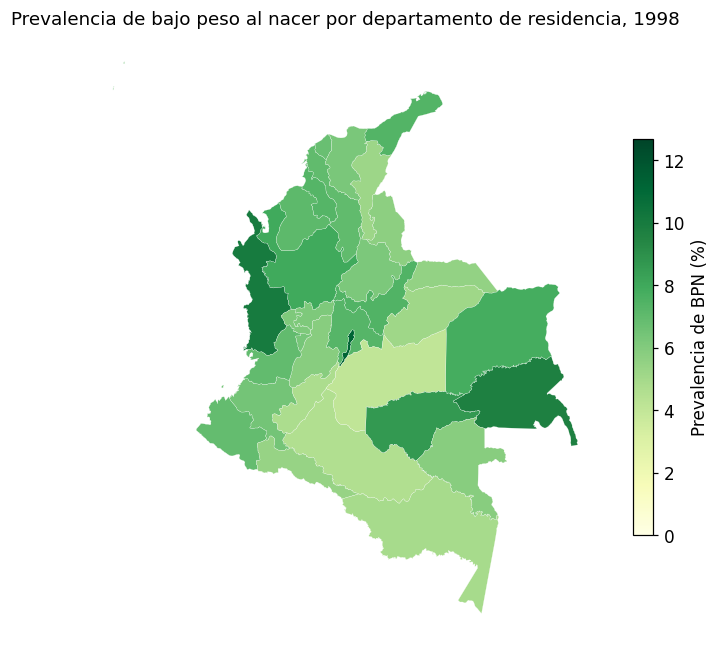

mapa estatico guardado: mapa_municipios_1998.pdf (907/1127 poligonos con dato)


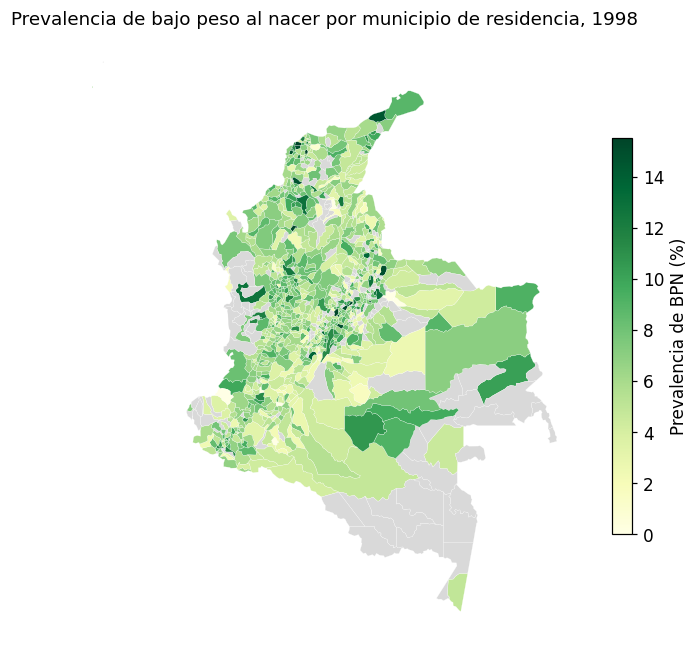

mapa estatico guardado: mapa_departamentos_2024.pdf (36/36 poligonos con dato)


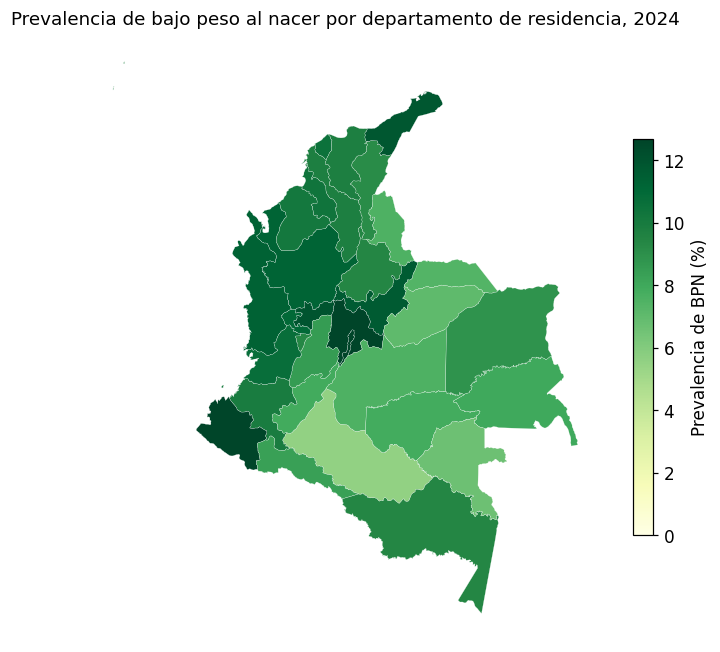

mapa estatico guardado: mapa_municipios_2024.pdf (804/1127 poligonos con dato)


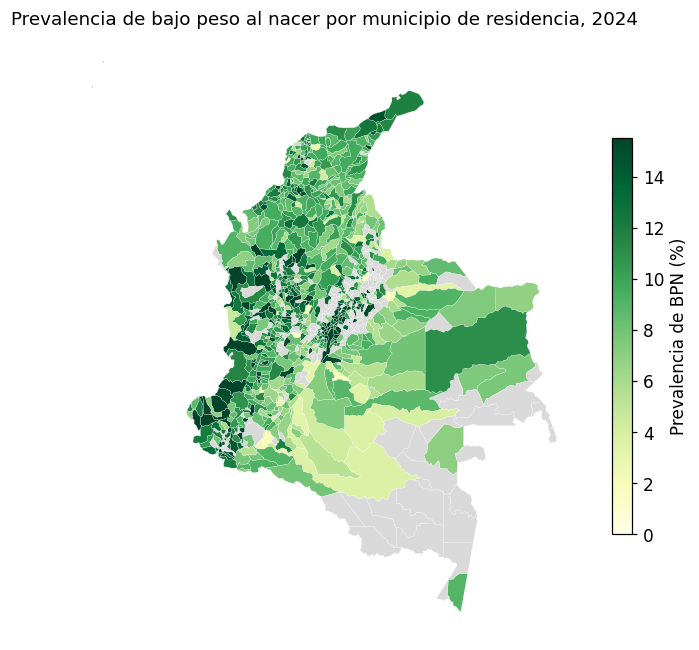


Para insertarlos en la tesis:
  \includegraphics[width=0.48\textwidth]{figuras/mapa_departamentos_1998.pdf}
  \includegraphics[width=0.48\textwidth]{figuras/mapa_departamentos_2024.pdf}


In [6]:
# ---------------------------------------------------------------------------
# Mapas estaticos (PDF vectorial para LaTeX)
# ---------------------------------------------------------------------------

ANIOS_FIGURA = [1998, 2024]

for anio in ANIOS_FIGURA:
    # --- Departamentos ---
    d = prev_dpto[prev_dpto["ANIO"] == anio]
    # dict(zip(...)) en vez de set_index().to_dict(): mas directo y no crea
    # un DataFrame intermedio.
    # Se asigna a _ por la misma razon: mapa_estatico devuelve la ruta del PDF,
    # y sin asignar Jupyter la imprimiria al final de la celda.
    _ = mapa_estatico(
        valores=dict(zip(d["COD_DPTO_N"], d["prevalencia_pct"])),
        geo=geo_dpto, clave=clave_dpto,
        titulo=f"Prevalencia de bajo peso al nacer por departamento de residencia, {anio}",
        ruta_pdf=DIR_FIGURAS / f"mapa_departamentos_{anio}.pdf",
        vmin=vmin, vmax=vmax,   # MISMA escala que la animacion y que el otro anio
    )

    # --- Municipios ---
    m = prev_muni[prev_muni["ANIO"] == anio].dropna(subset=["prevalencia_pct"])
    _ = mapa_estatico(
        valores=dict(zip(m["DIVIPOLA"], m["prevalencia_pct"])),
        geo=geo_muni, clave=clave_muni,
        titulo=f"Prevalencia de bajo peso al nacer por municipio de residencia, {anio}",
        ruta_pdf=DIR_FIGURAS / f"mapa_municipios_{anio}.pdf",
        vmin=vmin_m, vmax=vmax_m,
    )

print("\nPara insertarlos en la tesis:")
print(r"  \includegraphics[width=0.48\textwidth]{figuras/mapa_departamentos_1998.pdf}")
print(r"  \includegraphics[width=0.48\textwidth]{figuras/mapa_departamentos_2024.pdf}")

**Cómo se lee esta salida.**

- La línea de cada mapa dice cuántos polígonos tienen dato. En 1998, el mapa municipal va a
  tener bastantes menos que en 2024: **esa diferencia es información**, no un defecto.
- Ponlos lado a lado en la tesis, 1998 y 2024, en una figura de dos paneles. La comparación
  visual con escala común es el argumento.
- Si el PDF pesa más de 1 MB, la geometría municipal es demasiado detallada para el tamaño
  al que se va a imprimir. Se puede simplificar; dímelo.

**Pie de figura que necesita el manuscrito.** Debe incluir: la fuente de la geometría
(Marco Geoestadístico Nacional, DANE), el umbral de supresión (50 nacimientos), qué
significa el gris (sin dato o por debajo del umbral) y que la prevalencia es cruda.

## 6. Ordenamiento de departamentos y cambio en el período

**Qué hacemos.** La tabla que acompaña a los mapas: cada departamento con su prevalencia al
principio y al final, y el cambio.

**Por qué hace falta además del mapa.** Un mapa se lee de un vistazo pero no se cita. Nadie
puede escribir «Chocó pasó del X % al Y %» mirando colores. La tabla da los números; el
mapa da la intuición espacial. Van juntos.

**Decisión sobre los años extremos.** En vez de 1998 y 2024 sueltos, se promedian los tres
primeros y los tres últimos años. Un año concreto puede ser atípico por azar, sobre todo en
departamentos pequeños; el trienio es más estable y no cambia la interpretación.

In [7]:
# ---------------------------------------------------------------------------
# Cambio por departamento entre los trienios extremos
# ---------------------------------------------------------------------------

INICIO = [1998, 1999, 2000]
FINAL = [2022, 2023, 2024]

def prevalencia_trienio(tabla, anios):
    """
    Prevalencia agregada de un trienio.

    OJO: se suman casos y denominadores y se divide al final. NO se promedian
    las tres prevalencias anuales. Promediar proporciones da mas peso a los
    anios con menos nacimientos, que es justo al reves de lo que queremos.
    """
    t = tabla[tabla["ANIO"].isin(anios)]
    g = t.groupby("COD_DPTO_N")[["n", "casos"]].sum()
    return (g["casos"] / g["n"] * 100).rename("prev")

ini = prevalencia_trienio(prev_dpto, INICIO)
fin = prevalencia_trienio(prev_dpto, FINAL)

cambio = pd.concat([ini.rename("inicio_pct"), fin.rename("final_pct")], axis=1)
cambio["cambio_pp"] = cambio["final_pct"] - cambio["inicio_pct"]     # puntos porcentuales
cambio["cambio_rel_pct"] = (cambio["final_pct"] / cambio["inicio_pct"] - 1) * 100

# Nombre del departamento, desde la geometria: evita mantener un diccionario
# de nombres aparte que habria que actualizar a mano.
nombres = {f["properties"][clave_dpto]: f["properties"]["NOMBRE_DPT"]
           for f in geo_dpto["features"]}
cambio["departamento"] = cambio.index.map(nombres)

cambio = (cambio.reset_index()
                .rename(columns={"COD_DPTO_N": "codigo"})
                [["codigo", "departamento", "inicio_pct", "final_pct",
                  "cambio_pp", "cambio_rel_pct"]]
                .sort_values("final_pct", ascending=False))

guardar_tabla(cambio, "cambio_territorial_departamentos", decimales=2)

print("Los cinco de mayor prevalencia al final del periodo:")
print(cambio.head(5).to_string(index=False))
print("\nLos cinco de mayor aumento en puntos porcentuales:")
print(cambio.nlargest(5, "cambio_pp").to_string(index=False))
print("\nDepartamentos donde la prevalencia BAJO:")
bajaron = cambio[cambio["cambio_pp"] < 0]
print(bajaron.to_string(index=False) if len(bajaron)
      else "  ninguno: subio en los 33")

cambio

tabla guardada: cambio_territorial_departamentos.csv y cambio_territorial_departamentos.tex
Los cinco de mayor prevalencia al final del periodo:
codigo          departamento  inicio_pct  final_pct  cambio_pp  cambio_rel_pct
    11 SANTAFE DE BOGOTA D.C   10.913750  15.854872   4.941122       45.274283
    25          CUNDINAMARCA    7.809999  13.723892   5.913893       75.722076
    52                NARIÑO    6.926628  12.613970   5.687342       82.108374
    15                BOYACA    7.408313  11.576590   4.168277       56.264870
    44            LA GUAJIRA    7.262229  11.375782   4.113553       56.643114

Los cinco de mayor aumento en puntos porcentuales:
codigo          departamento  inicio_pct  final_pct  cambio_pp  cambio_rel_pct
    25          CUNDINAMARCA    7.809999  13.723892   5.913893       75.722076
    52                NARIÑO    6.926628  12.613970   5.687342       82.108374
    17                CALDAS    6.113847  11.240559   5.126712       83.854107
    11 SANTAF

,codigo,departamento,inicio_pct,final_pct,cambio_pp,cambio_rel_pct
2,11,SANTAFE DE BOGOTA D.C,10.913750,15.854872,4.941122,45.274283
10,25,CUNDINAMARCA,7.809999,13.723892,5.913893,75.722076
16,52,NARIÑO,6.926628,12.613970,5.687342,82.108374
4,15,BOYACA,7.408313,11.576590,4.168277,56.264870
13,44,LA GUAJIRA,7.262229,11.375782,4.113553,56.643114
11,27,CHOCO,8.890763,11.292339,2.401577,27.012042
5,17,CALDAS,6.113847,11.240559,5.126712,83.854107
19,66,RISARALDA,6.398796,11.073910,4.675113,73.062388
0,05,ANTIOQUIA,8.009856,11.022546,3.012690,37.612289
21,70,SUCRE,7.220123,10.604850,3.384727,46.879082


**Cómo se lee esta salida.**

- **Si la prevalencia subió en los 33 departamentos**, el aumento es nacional y no
  atribuible a unos pocos territorios. Eso refuerza la hipótesis de que hay un componente
  de registro detrás, porque un cambio epidemiológico real rara vez es tan uniforme.
- **Si algunos bajaron**, esos son los casos interesantes: ¿qué tienen en común? Es material
  de discusión.
- **`cambio_pp` frente a `cambio_rel_pct`.** No dicen lo mismo. Pasar del 4 % al 6 % son 2
  puntos porcentuales y un 50 % de aumento relativo. Pasar del 10 % al 12 % son los mismos
  2 puntos pero solo un 20 % relativo. **Para la desigualdad importa el relativo**; para el
  número de bebés afectados importa el absoluto. Di siempre cuál estás usando.
- **Departamentos pequeños en los extremos.** Amazonas, Vaupés, Guainía tienen pocos
  nacimientos y sus cambios son inestables. Míralos contra la columna `n` antes de
  destacarlos en el texto.

**Qué va al manuscrito.** La tabla completa al Capítulo 5, Sección 5.1.5. En el texto, los
tres departamentos de mayor prevalencia final y los tres de mayor aumento, siempre con la
advertencia de que son cifras crudas.

## 5. Quién encabeza cada año: la carrera de barras

**Qué hacemos.** Un gráfico de barras animado con los 15 departamentos de mayor prevalencia
en cada año, **reordenados en cada fotograma**.

**Por qué esto además del mapa.** El mapa responde *dónde*, pero no permite leer el
**orden**. A ojo, sobre un mapa, nadie distingue si Chocó está por encima o por debajo de
La Guajira, y mucho menos si se adelantaron el uno al otro en 2015. Las barras ordenadas
hacen visible exactamente eso.

**Qué mirar.** El movimiento vertical. Un departamento que sube de posición se ve escalar;
uno que sale del top desaparece. **El reordenamiento es el resultado**, no un adorno.

**Por qué la escala del eje horizontal es fija.** Si cada año se autoescalara, la barra más
larga llenaría siempre el ancho y el aumento general del período sería invisible. Con
escala fija, las barras crecen a lo largo de la animación, y eso también es información.

In [8]:
# ---------------------------------------------------------------------------
# Carrera de barras: los 15 departamentos de mayor prevalencia, por anio
# ---------------------------------------------------------------------------

# OJO AL SIGNO IGUAL. La funcion ya llama a fig.show() por dentro, y ademas
# DEVUELVE la figura. Si la llamada queda como ultima expresion de la celda,
# Jupyter muestra automaticamente lo devuelto y el mapa aparece DOS VECES.
# Asignar el resultado a una variable evita ese segundo dibujado, y de paso
# deja la figura disponible por si se quiere ajustar algo despues.
fig_barras = barras_animadas(
    tabla=prev_dpto,
    nombres=nombres_dpto,          # {codigo: nombre}, sacado de la geometria
    col_codigo="COD_DPTO_N", col_valor="prevalencia_pct", col_tiempo="ANIO",
    titulo="Departamentos de residencia con mayor prevalencia de bajo peso al nacer",
    ruta_html=DIR_MAPAS / "barras_departamentos_1998_2024.html",
    top=15,
    duracion_ms=700,
)

carrera de barras guardada: barras_departamentos_1998_2024.html (56 KB, 27 anios)


**Cómo se lee esta salida.**

- **Un departamento que sube posiciones no necesariamente empeoró.** Puede que los demás
  mejoraran. La posición es *relativa*; el valor absoluto está en la barra.
- **Departamentos pequeños en los primeros puestos.** Amazonas, Vaupés y Guainía tienen
  pocos nacimientos: su prevalencia oscila mucho por azar y pueden entrar y salir del top
  sin que nada real haya cambiado. Antes de mencionar uno en el texto, mira su `n`.
- **Si las barras casi no se reordenan** en 27 años, el hallazgo es ese: la jerarquía
  territorial del bajo peso al nacer en Colombia es **estable**. Es un resultado, y de los
  buenos: significa que los determinantes territoriales son estructurales y no coyunturales.
- **Si se reordenan mucho**, hay que preguntarse cuánto de ese movimiento es señal y cuánto
  es ruido de denominadores pequeños. El bloque siguiente ayuda a decidirlo.

## 6. Tabla de liderazgo y cambios de posición

**Qué hacemos.** Dos tablas. La primera, quién encabeza cada año. La segunda, cuánto subió
o bajó cada departamento en el ranking entre el principio y el final del período.

**Por qué hacen falta si ya tenemos la animación.** Porque **una animación no se puede
citar**. En el manuscrito hay que poder escribir «en 1998 encabezaba X con 9,4 % y en 2024
lo hace Y con 13,1 %», y eso sale de una tabla, no de un vídeo.

**Por qué el cambio de posición y no solo el cambio de valor.** Si la prevalencia sube en
todo el país, todos los valores suben y la comparación no distingue nada. La **posición**
es relativa: solo cambia cuando un departamento empeora o mejora *respecto a los demás*.
Esa es la pregunta que estás haciendo.

**Atención al signo, que es contraintuitivo.** `cambio_posicion` positivo significa que el
departamento **subió en el ranking**, es decir que **empeoró** en términos de salud. Está
declarado así en el código; si lo mencionas en la sustentación, dilo explícito.

In [9]:
# ---------------------------------------------------------------------------
# Quien encabeza cada anio, y quien se movio en el ranking
# ---------------------------------------------------------------------------

# --- Tabla 1: los 5 primeros de cada anio ---------------------------------
lideres = tabla_lideres(
    prev_dpto, nombres_dpto,
    col_codigo="COD_DPTO_N", col_valor="prevalencia_pct", col_tiempo="ANIO",
    top=5,
)
guardar_tabla(lideres, "lideres_por_anio", decimales=2)

# Vista compacta: una fila por anio con los cinco nombres en orden. Es lo que
# se mira de un vistazo; la tabla larga es la que se guarda para el apendice.
compacta = (lideres.sort_values(["ANIO", "posicion"])
                   .groupby("ANIO")["territorio"]
                   .apply(lambda s: "  >  ".join(s))
                   .reset_index()
                   .rename(columns={"territorio": "de mayor a menor prevalencia"}))

print("QUIEN ENCABEZA CADA ANIO (los 5 de mayor prevalencia)")
print(compacta.to_string(index=False))

# --- Tabla 2: cambios de posicion entre los extremos ----------------------
cambios = cambios_de_posicion(
    prev_dpto, nombres_dpto,
    col_codigo="COD_DPTO_N", col_valor="prevalencia_pct", col_tiempo="ANIO",
)
guardar_tabla(cambios, "cambios_de_posicion_departamentos", decimales=2)

print("\n\nLOS QUE MAS SUBIERON EN EL RANKING (empeoraron respecto a los demas)")
print(cambios.nlargest(5, "cambio_posicion").to_string(index=False))

print("\n\nLOS QUE MAS BAJARON EN EL RANKING (mejoraron respecto a los demas)")
print(cambios.nsmallest(5, "cambio_posicion").to_string(index=False))

# Estabilidad del ranking. La correlacion de Spearman entre las posiciones de
# los dos anios resume, en un numero, si la jerarquia territorial se mantuvo.
from scipy.stats import spearmanr
cols_pos = [c for c in cambios.columns if c.startswith("posicion_")]
rho, pval = spearmanr(cambios[cols_pos[0]], cambios[cols_pos[1]])
print("\n\nESTABILIDAD DE LA JERARQUIA TERRITORIAL")
print(f"  Spearman entre {cols_pos[0]} y {cols_pos[1]}: rho = {rho:.3f}")
print(f"  valor p: {pval:.2e}  (no lo cites: con 33 unidades sale significativo casi siempre)")

compacta

tabla guardada: lideres_por_anio.csv y lideres_por_anio.tex
QUIEN ENCABEZA CADA ANIO (los 5 de mayor prevalencia)
 ANIO                                                                                                  de mayor a menor prevalencia
 1998                                                        Santafe De Bogota D.C  >  Choco  >  Guainia  >  Guaviare  >  Antioquia
 1999                                                   Santafe De Bogota D.C  >  Antioquia  >  Guaviare  >  Cundinamarca  >  Choco
 2000                                                     Santafe De Bogota D.C  >  Guainia  >  Choco  >  Cundinamarca  >  Guaviare
 2001                                                        Santafe De Bogota D.C  >  Choco  >  Guaviare  >  Antioquia  >  Cordoba
 2002                                                     Santafe De Bogota D.C  >  Choco  >  Antioquia  >  Boyaca  >  Cundinamarca
 2003    Santafe De Bogota D.C  >  Choco  >  Cundinamarca  >  Archipielago De San Andres Provi

,ANIO,de mayor a menor prevalencia
0,1998,Santafe De Bogota D.C > Choco > Guainia >...
1,1999,Santafe De Bogota D.C > Antioquia > Guavia...
2,2000,Santafe De Bogota D.C > Guainia > Choco >...
3,2001,Santafe De Bogota D.C > Choco > Guaviare ...
4,2002,Santafe De Bogota D.C > Choco > Antioquia ...
5,2003,Santafe De Bogota D.C > Choco > Cundinamar...
6,2004,Santafe De Bogota D.C > Cundinamarca > Arc...
7,2005,Santafe De Bogota D.C > Cundinamarca > Gua...
8,2006,Santafe De Bogota D.C > Cundinamarca > Ant...
9,2007,Santafe De Bogota D.C > Cundinamarca > Ant...


**Cómo se lee esta salida.**

**La tabla compacta** te da, de un vistazo, si el orden cambia. Si los mismos tres o cuatro
nombres aparecen en cabeza los 27 años, la desigualdad territorial es **estructural**.

**La correlación de Spearman entre las posiciones inicial y final** resume eso en un número:

| ρ | Lectura |
|---|---|
| **> 0,8** | La jerarquía apenas se movió. Los departamentos que estaban peor en 1998 siguen peor en 2024. Es un hallazgo fuerte |
| **0,4 – 0,8** | Reordenamiento parcial. Hay que identificar qué departamentos se movieron y por qué |
| **< 0,4** | Reordenamiento profundo. Antes de creerlo, descarta que sea ruido de denominadores pequeños |

**El valor p no se cita**: con 33 departamentos, ρ = 0,4 ya sale significativo. Lo que se
interpreta es la magnitud.

**Qué va al manuscrito.**

- La tabla compacta al Capítulo 5, Sección 5.1.5; la de líderes completa, al apéndice
- Un par de frases con quién encabeza al principio y al final del período
- **La ρ de Spearman como argumento de la discusión**: si la jerarquía es estable, la
  desigualdad territorial no es coyuntural, y eso da peso a los modelos multinivel de la
  Fase 4, que es donde se cuantifica cuánta variación es atribuible al lugar

**Precaución obligatoria.** Todo esto sigue siendo **prevalencia cruda**. Un departamento
encabeza la lista por su composición sociodemográfica tanto como por algo propio del
territorio. Separarlas es trabajo de la Fase 4, no de estas tablas.

## 7. Cierre

In [10]:
# ---------------------------------------------------------------------------
# Cierre
# ---------------------------------------------------------------------------

from util import versiones

# Se imprime la RUTA COMPLETA, no solo el nombre: asi se puede copiar y pegar
# en el Explorador de Windows sin tener que buscarla.
print("MAPAS ANIMADOS")
print("Copia una de estas rutas, pegala en la barra del Explorador y pulsa Enter.")
print("Se abriran en el navegador, con el boton Reproducir.\n")
for f in sorted(DIR_MAPAS.glob("*.html")):
    print(f"  {f.stat().st_size / 1024**2:6.2f} MB   {f}")

print("\nFIGURAS PARA EL MANUSCRITO (PDF vectorial + PNG para revisar)")
for f in sorted(DIR_FIGURAS.glob("mapa_*.pdf")):
    print(f"  {f.stat().st_size / 1024:8.1f} KB   {f}")

if not list(DIR_MAPAS.glob("*.html")):
    print("\n  NO SE GENERO NINGUN MAPA. Alguna celda anterior fallo;")
    print("  revisa la primera que muestre un error en rojo.")

print("\n" + "=" * 60)
versiones()

MAPAS ANIMADOS
Copia una de estas rutas, pegala en la barra del Explorador y pulsa Enter.
Se abriran en el navegador, con el boton Reproducir.

    3.10 MB   /Users/instructorzamora/Documents/Descarga/BPN_PORTATIL/codigo/salidas/mapas/atlas_bpn.html
    0.05 MB   /Users/instructorzamora/Documents/Descarga/BPN_PORTATIL/codigo/salidas/mapas/barras_departamentos_1998_2024.html
    1.95 MB   /Users/instructorzamora/Documents/Descarga/BPN_PORTATIL/codigo/salidas/mapas/conglomerados_lisa_1998_2024.html
    1.34 MB   /Users/instructorzamora/Documents/Descarga/BPN_PORTATIL/codigo/salidas/mapas/mapa_departamentos_1998_2024.html
    1.95 MB   /Users/instructorzamora/Documents/Descarga/BPN_PORTATIL/codigo/salidas/mapas/mapa_municipios_1998_2024.html

FIGURAS PARA EL MANUSCRITO (PDF vectorial + PNG para revisar)
     239.7 KB   /Users/instructorzamora/Documents/Descarga/BPN_PORTATIL/codigo/salidas/figuras/mapa_calor_prevalencia_municipal_05.pdf
      78.8 KB   /Users/instructorzamora/Documents/Des

## Qué sigue

Los mapas describen. **No explican nada.** Todo lo que se ve aquí es prevalencia cruda, sin
ajustar por composición: un departamento puede tener alta prevalencia sencillamente porque
sus madres son más jóvenes o tienen menor nivel educativo, no por nada propio del
territorio.

Separar lo que es del lugar de lo que es de las personas que viven en él es exactamente el
trabajo de **`04_multinivel.ipynb`**. El coeficiente de correlación intraclase del modelo
vacío responde, con un número, la pregunta que estos mapas solo sugieren: **cuánta de la
variación en bajo peso es atribuible al municipio y al departamento**.

Antes de seguir, comprueba:

- [ ] El cruce municipal superó el 90 %
- [ ] El mapa animado se abre y reproduce en el navegador
- [ ] Los cuatro PDF existen y tienen polígonos con dato
- [ ] Sabes cuántas celdas municipio-año se suprimieron por el umbral

**Pégame la salida del bloque 2 y del bloque 6** y reviso el cruce y el ordenamiento
territorial contra lo que dice el manuscrito.